In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [3]:
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm
from scipy.odr import Model, Data, ODR

In [4]:
def flag_bad(x):
    """
    It returns True if the input is NaN or Inf, and False otherwise

    :param x: the input data
    :return: A boolean array of the same shape as x, where True indicates that the corresponding element
    of x is NaN or +/-inf.
    """
    return np.isnan(x) | np.isinf(x)


def remove_bad(xs):
    if xs[0].ndim == 1:
        n_sample = len(xs[0])
    else:
        n_sample = xs[0].shape[0]
    bad = np.zeros(n_sample, dtype=bool)
    for x in xs:
        if x.ndim == 1:
            bad |= flag_bad(x)
        else:
            bad |= flag_bad(x).any(axis=1)
    return [x[~bad] for x in xs]


def all_asarray(xs):
    return [np.asarray(x) for x in xs]


def get_linear_model(k, b):

    def func(x):
        return k * x + b

    return func


def preprocess(xs):
    '''
    allasarray + remove_bad
    '''
    return remove_bad(all_asarray(xs))

def xy2logxy(x, y, x_err, y_err):
    logx = np.log10(x)
    logy = np.log10(y)
    logx_err = x_err / (x * np.log(10))
    logy_err = y_err / (y * np.log(10))
    return logx, logy, logx_err, logy_err

def get_OLS(x, y, return_res=False):
    # y = kx + b
    x, y = preprocess([x, y])

    X = sm.add_constant(x)
    model = sm.OLS(y, X)
    results = model.fit()

    if return_res:
        return results

    b, k = results.params
    b_err, k_err = results.HC1_se

    func = get_linear_model(k, b)

    std = np.std(func(x) - y)

    return {'k': (k, k_err), 'b': (b, b_err), 'std': std, 'func': func}

def get_WLS(x, y, y_err, return_res=False):
    # y = kx + b
    x, y, y_err = preprocess([x, y, y_err])

    X = sm.add_constant(x)
    model = sm.WLS(y, X, weights=1. / np.square(y_err))
    results = model.fit()

    if return_res:
        return results

    b, k = results.params
    b_err, k_err = results.HC1_se

    func = get_linear_model(k, b)

    std = np.std(func(x) - y)

    return {'k': (k, k_err), 'b': (b, b_err), 'std': std, 'func': func}


def get_ODR(x, y, x_err=None, y_err=None, return_res=False):

    # https://docs.scipy.org/doc/scipy/reference/odr.html

    def f(B, x):
        return B[0] * x + B[1]

    if x_err is None:
        x_err = np.ones_like(x)
    if y_err is None:
        y_err = np.ones_like(y)

    x, y, x_err, y_err = preprocess([x, y, x_err, y_err])

    linear = Model(f)
    mydata = Data(x, y, wd=1. / np.square(x_err), we=1. / np.square(y_err))
    myodr = ODR(mydata, linear, beta0=[1., 0.])
    results = myodr.run()

    if return_res:
        return results

    k, b = results.beta
    k_err, b_err = results.sd_beta

    func_xy = get_linear_model(k, b)
    func_yx = get_linear_model(1 / k, -b / k)

    x_std = np.std(func_yx(y) - x)
    y_std = np.std(func_xy(x) - y)

    d_std = np.std((func_xy(x) - y) / np.sqrt(k**2 + 1))

    return {
        'k': (k, k_err),
        'b': (b, b_err),
        'x_std': x_std,
        'y_std': y_std,
        'd_std': d_std,
        'func_xy': func_xy,
        'func_yx': func_yx
    }

In [5]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = np.random.uniform(0.1, 10, size=N)

y = 10 ** (k * np.log10(x) + b + np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

2024-10-29 17:13:35.112343: E external/xla/xla/stream_executor/cuda/cuda_driver.cc:266] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


RuntimeError: Unable to initialize backend 'cuda': FAILED_PRECONDITION: No visible GPU devices. (you may need to uninstall the failing plugin package, or set JAX_PLATFORMS=cpu to skip this backend.)

In [6]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/tmp/ipykernel_1704853/3205802666.py:45: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/tmp/ipykernel_1704853/3205802666.py:46: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)
2024-10-29 17:03:27.824577: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


In [7]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

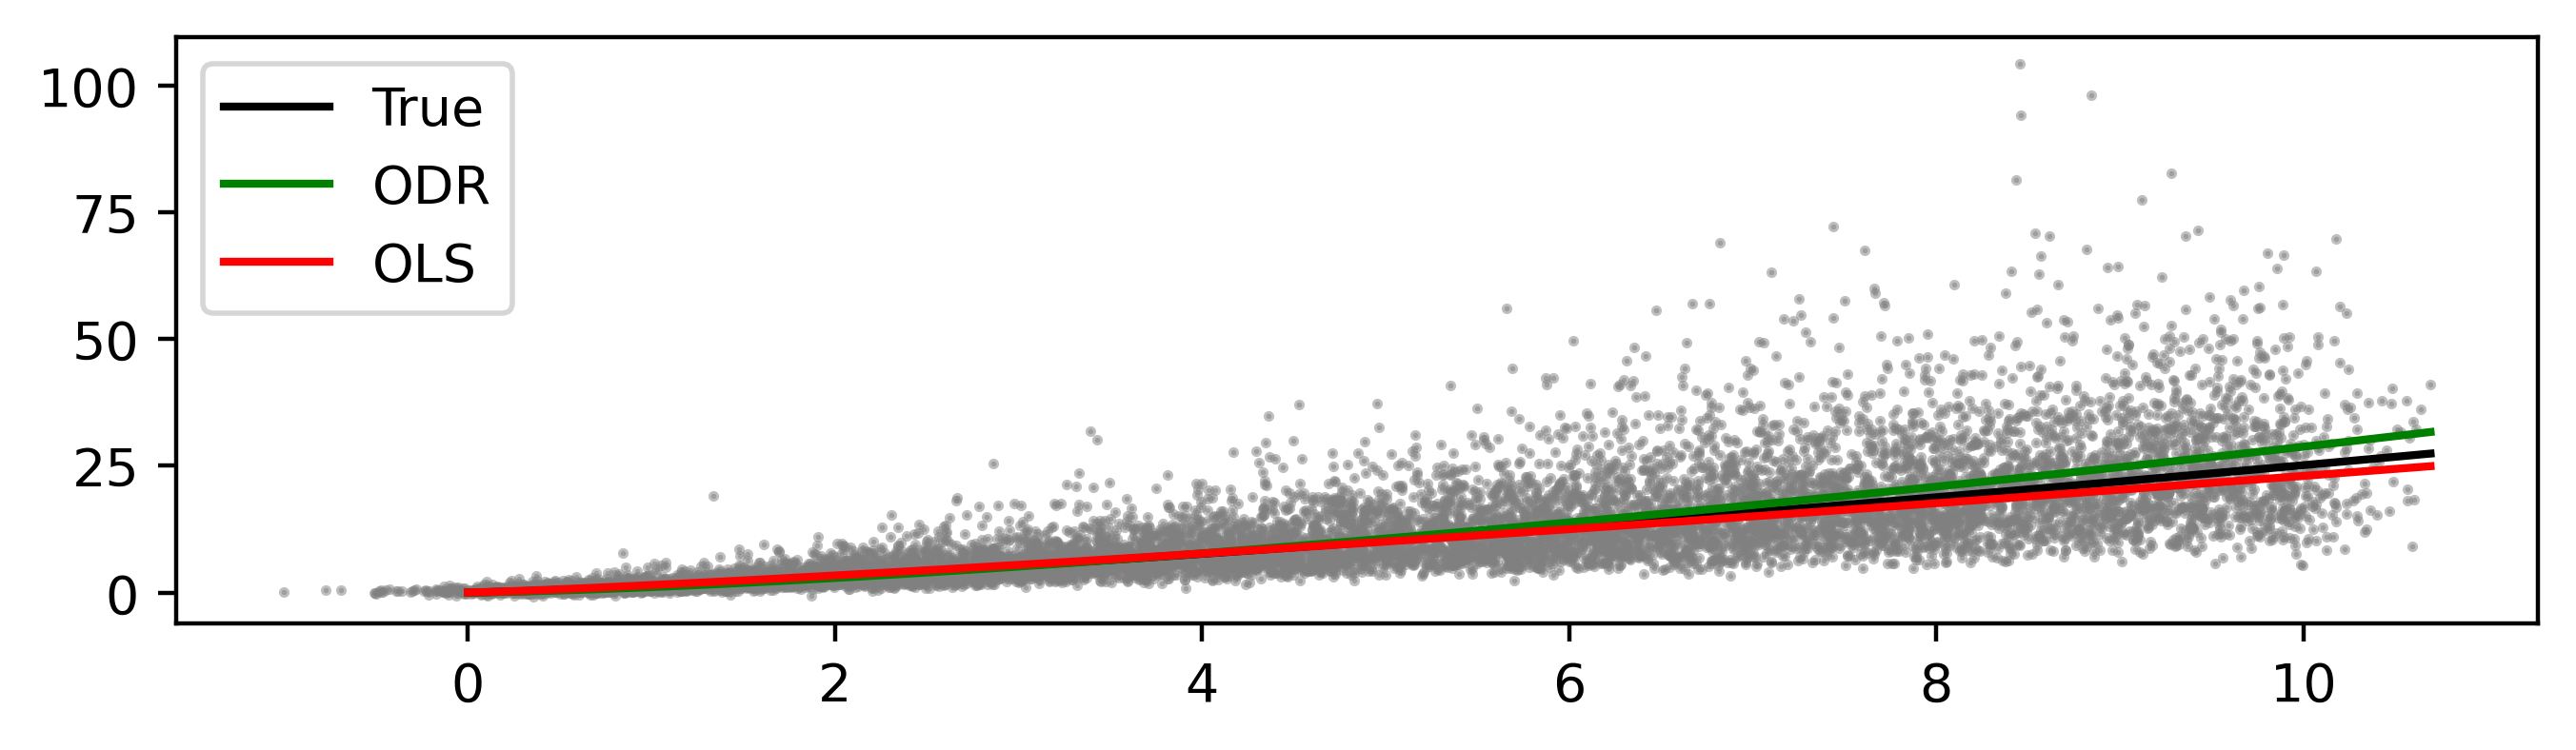

In [8]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [6]:
from rarden.api.fitter import FlowVI, RegressorLogLinearML, RegressorLogLinearKS
from rarden.transfer import neglogplus

In [7]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=neglogplus)

xflow.fit(x_obs, x_err, verbose=True)

100%|██████████| 100/100 [00:13<00:00,  7.37it/s]


step 0: loss 0.8914508819580078
step 10: loss 0.8669294714927673
step 20: loss 0.8605781197547913
step 30: loss 0.8582280874252319
step 40: loss 0.8563157916069031
step 50: loss 0.8564456105232239
step 60: loss 0.8562459945678711


In [8]:
xflow.ks_test(x_obs, x_err, 10000)

(0.01689995639026165, 0.31037998299547936)

In [9]:
yflow = FlowVI(transfer=neglogplus)

yflow.fit(y_obs, y_err, verbose=True)

100%|██████████| 100/100 [00:13<00:00,  7.60it/s]


step 0: loss 2.094101667404175
step 10: loss 2.035270929336548
step 20: loss 2.029787302017212
step 30: loss 2.0258543491363525
step 40: loss 2.023799419403076
step 50: loss 2.026794672012329
step 60: loss 2.0219733715057373


In [10]:
yflow.ks_test(y_obs, y_err, 10000)

(0.01625000685453415, 0.35640628468828733)

### ML Based Method

In [11]:
regressor_logLinear_ML = RegressorLogLinearML(xflow, yflow)

In [12]:
res_ML = regressor_logLinear_ML.fit(x_obs, x_err, y_obs, y_err, [1., 0., 0.1], verbose=True)

0 1.0168716 0.021737775 0.17691304 -3.145739
1000 1.2583137 0.12506087 0.20083253 -2.0544863
2000 1.2902039 0.1022778 0.20061974 -2.0527537
3000 1.2993712 0.095716774 0.20062225 -2.0526109
4000 1.3020462 0.093801595 0.2006281 -2.0525987
5000 1.3028274 0.09324151 0.20063022 -2.0525975
converged, so stop with 5000 iterations


In [13]:
print('ML fitted:', *res_ML)
print('Truth:', k, b, sig)

ML fitted: 1.3028274 0.09324151 0.20063022
Truth: 1.3 0.1 0.2


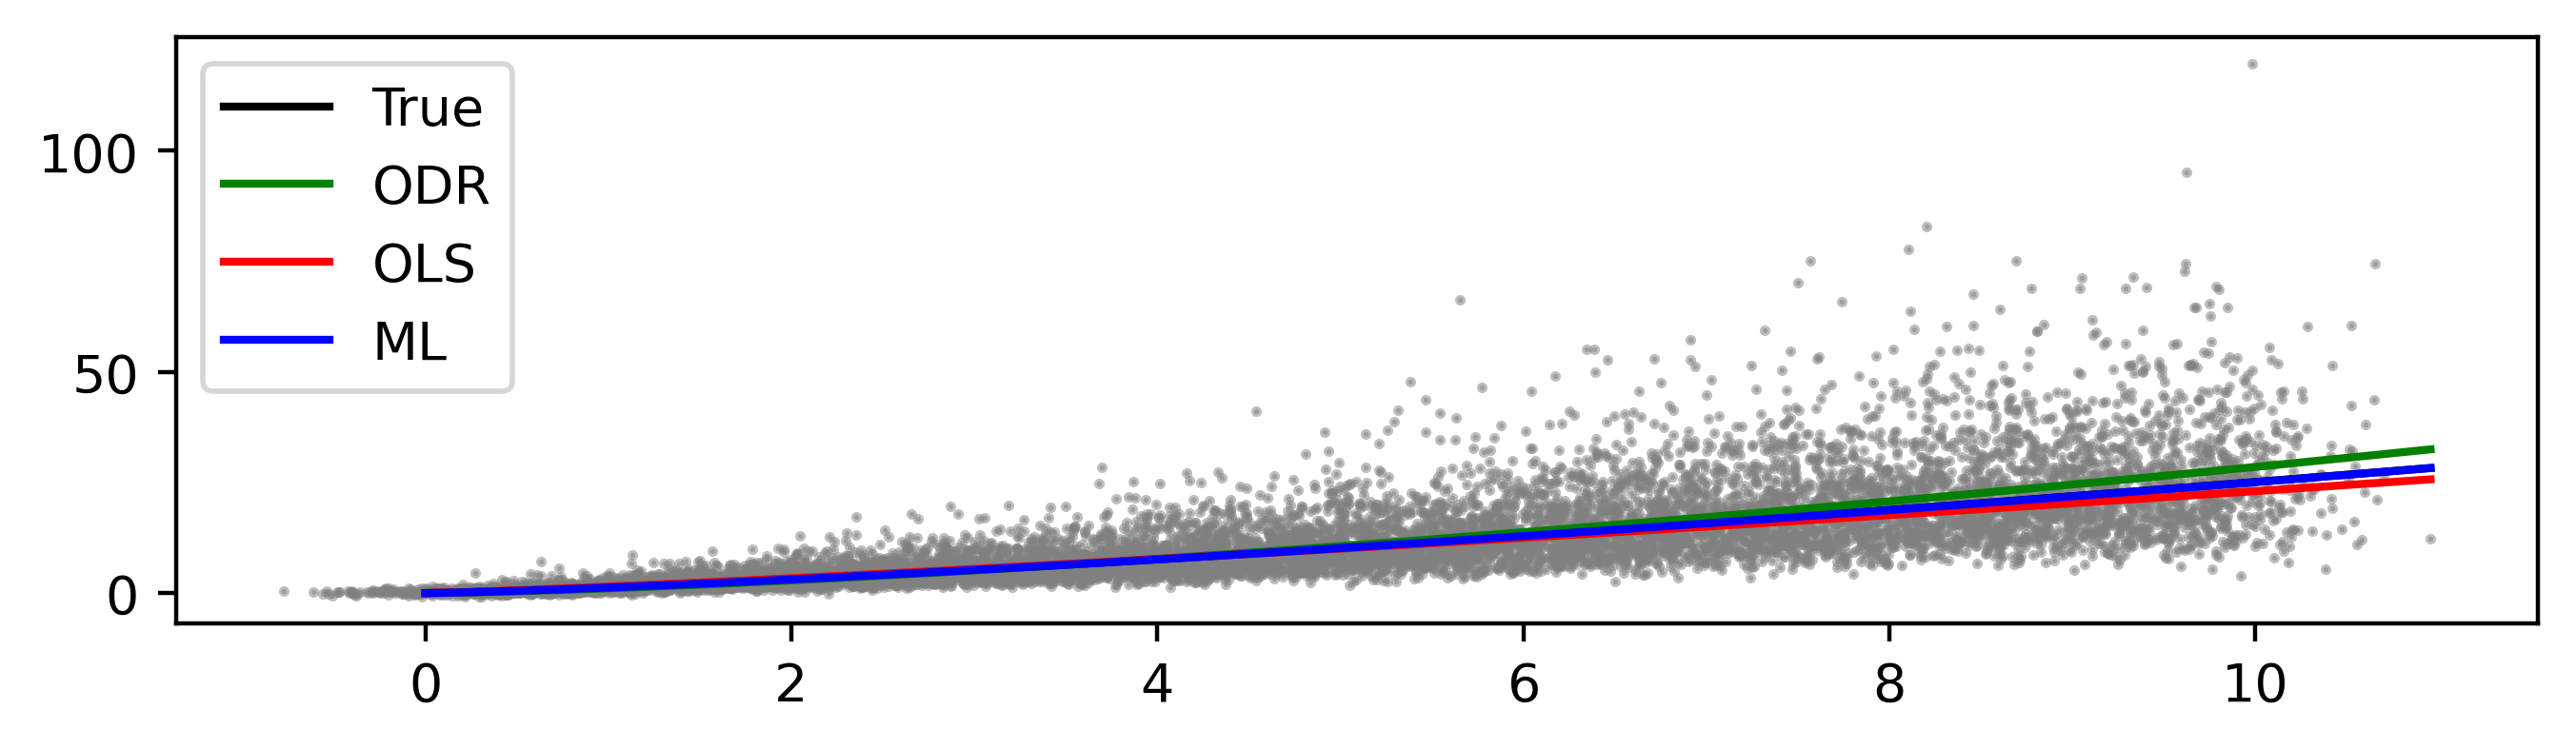

In [17]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))
yy_ML = 10 ** (res_ML[0] * np.log10(xx) + res_ML[1])

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')
plt.plot(xx, yy_ML, color='blue', label='ML')

plt.legend()

In [18]:
x_obs_gen, y_obs_gen, x_err_gen, y_err_gen, x_gen, y_gen = regressor_logLinear_ML.sample(
    res_ML)

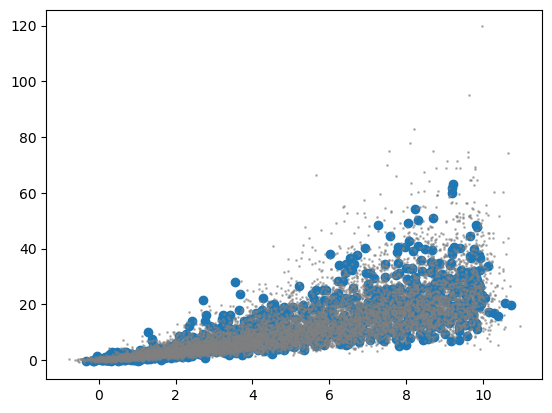

In [19]:
plt.scatter(x_obs_gen, y_obs_gen)
plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)

### KS Based Method

In [20]:
regressor_logLinear_KS = RegressorLogLinearKS(xflow, yflow)

In [21]:
params_mean, params_std, res_arr = regressor_logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

/home/jingtao/software/anaconda3/envs/rarden/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.227 +/- 0.149
b: 0.150 +/- 0.109
sig: 0.206 +/- 0.047
----
k: 1.271 +/- 0.109
b: 0.117 +/- 0.084
sig: 0.204 +/- 0.038
----
k: 1.267 +/- 0.089
b: 0.121 +/- 0.071
sig: 0.203 +/- 0.038
----
k: 1.262 +/- 0.096
b: 0.126 +/- 0.076
sig: 0.205 +/- 0.035
----
k: 1.258 +/- 0.097
b: 0.127 +/- 0.077
sig: 0.202 +/- 0.037
----
k: 1.283 +/- 0.100
b: 0.109 +/- 0.077
sig: 0.204 +/- 0.038
----
k: 1.280 +/- 0.088
b: 0.112 +/- 0.072
sig: 0.200 +/- 0.037
----
k: 1.265 +/- 0.096
b: 0.124 +/- 0.074
sig: 0.213 +/- 0.038
----
k: 1.264 +/- 0.094
b: 0.123 +/- 0.074
sig: 0.207 +/- 0.040
----
k: 1.261 +/- 0.101
b: 0.125 +/- 0.080
sig: 0.208 +/- 0.038
----
k: 1.246 +/- 0.093
b: 0.137 +/- 0.071
sig: 0.206 +/- 0.037
max iteration reached
[1.26593079 0.12183645 0.20519578] [0.08941198 0.06987475 0.03694608]


In [22]:
regressor_logLinear_KS_quantile = RegressorLogLinearKS(xflow, yflow, gen_new_grid='quantile')

In [23]:
params_mean, params_std, res_arr = regressor_logLinear_KS_quantile.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

----
k: 1.267 +/- 0.100
b: 0.119 +/- 0.081
sig: 0.209 +/- 0.040
----
k: 1.276 +/- 0.093
b: 0.111 +/- 0.074
sig: 0.201 +/- 0.038
----
k: 1.269 +/- 0.094
b: 0.117 +/- 0.074
sig: 0.205 +/- 0.036
----
k: 1.278 +/- 0.109
b: 0.112 +/- 0.085
sig: 0.208 +/- 0.044
----
k: 1.287 +/- 0.094
b: 0.107 +/- 0.075
sig: 0.203 +/- 0.040
----
k: 1.287 +/- 0.106
b: 0.105 +/- 0.083
sig: 0.210 +/- 0.041
----
k: 1.273 +/- 0.096
b: 0.114 +/- 0.075
sig: 0.202 +/- 0.037
----
k: 1.259 +/- 0.089
b: 0.125 +/- 0.071
sig: 0.211 +/- 0.037
----
k: 1.267 +/- 0.084
b: 0.121 +/- 0.069
sig: 0.201 +/- 0.037
----
k: 1.258 +/- 0.094
b: 0.126 +/- 0.074
sig: 0.206 +/- 0.036
----
k: 1.264 +/- 0.098
b: 0.125 +/- 0.077
sig: 0.203 +/- 0.040
max iteration reached
[1.26918283 0.11955436 0.20395747] [0.09104378 0.07213032 0.03878941]
